# Exercise: Cluster Iris Flowers with K-Means 🌸

In the lecture we clustered people by age & income. Now try **K-Means clustering** on the classic **iris flower** dataset.

Unlike the earlier lessons, this is **unsupervised** — we'll cluster the flowers *without* using their species labels, then check afterward how well the clusters line up with the real species.

Your tasks:
1. Use only the **`petal_length`** and **`petal_width`** features (drop the two sepal columns for simplicity).
2. Figure out whether **scaling** (e.g. `MinMaxScaler`) helps here.
3. Draw an **elbow plot** and use it to pick the optimal number of clusters, `k`.
4. Run K-Means with that `k` and visualize the clusters.

The dataset is `iris.csv` (columns: the four measurements plus `flower`, the true species — which we'll only peek at *after* clustering).

> Fill in the code under each step (hints are in the comments).

## Step 1 — Load the data and keep the petal features

Read `iris.csv`, then build `X` using only `petal_length` and `petal_width`.

In [7]:
# import pandas as pd
# from matplotlib import pyplot as plt
#
# df = pd.read_csv('iris.csv')
# X = df[['petal_length', 'petal_width']]
# df.head()
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('iris.csv')
X = df[['petal_length', 'petal_width']]
df.head()

,sepal_length,sepal_width,petal_length,petal_width,flower
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Step 2 — Look at the data

Make a scatter plot of `petal_length` (x) vs `petal_width` (y). How many natural groups do your eyes see?

Text(0, 0.5, 'Petal Width')

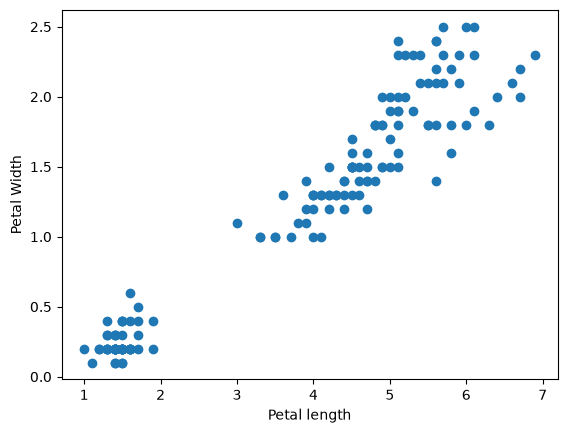

In [6]:
# plt.scatter(X['petal_length'], X['petal_width'])
# label the axes
plt.scatter(X.petal_length, X.petal_width)
plt.xlabel('Petal length')
plt.ylabel('Petal Width')

## Step 3 — Scaling: does it help?

K-Means uses distances, so features on different scales can distort the clusters. Scale `petal_length` and `petal_width` to 0–1 with `MinMaxScaler`.

*Think about it: the two petal features are already in a similar range (cm), so how big an effect do you expect scaling to have here?*

In [11]:
# from sklearn.preprocessing import MinMaxScaler
# scale petal_length and petal_width into X (0-1 range)
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaler.fit(X[['petal_length']])
pl_scaled = scaler.transform(X[['petal_length']])

scaler.fit(X[['petal_width']])
pw_scaled = scaler.transform(X[['petal_width']])

pl_scaled, pw_scaled

(array([[0.06779661],
        [0.06779661],
        [0.05084746],
        [0.08474576],
        [0.06779661],
        [0.11864407],
        [0.06779661],
        [0.08474576],
        [0.06779661],
        [0.08474576],
        [0.08474576],
        [0.10169492],
        [0.06779661],
        [0.01694915],
        [0.03389831],
        [0.08474576],
        [0.05084746],
        [0.06779661],
        [0.11864407],
        [0.08474576],
        [0.11864407],
        [0.08474576],
        [0.        ],
        [0.11864407],
        [0.15254237],
        [0.10169492],
        [0.10169492],
        [0.08474576],
        [0.06779661],
        [0.10169492],
        [0.10169492],
        [0.08474576],
        [0.08474576],
        [0.06779661],
        [0.08474576],
        [0.03389831],
        [0.05084746],
        [0.06779661],
        [0.05084746],
        [0.08474576],
        [0.05084746],
        [0.05084746],
        [0.05084746],
        [0.10169492],
        [0.15254237],
        [0

## Step 4 — Elbow plot

For `k` = 1 to 9, fit `KMeans` and record its `inertia_` (the sum of squared errors). Plot SSE vs `k`. The "elbow" — where the curve stops dropping steeply — is a good choice for `k`.

Text(0, 0.5, 'Sum of squared errors')

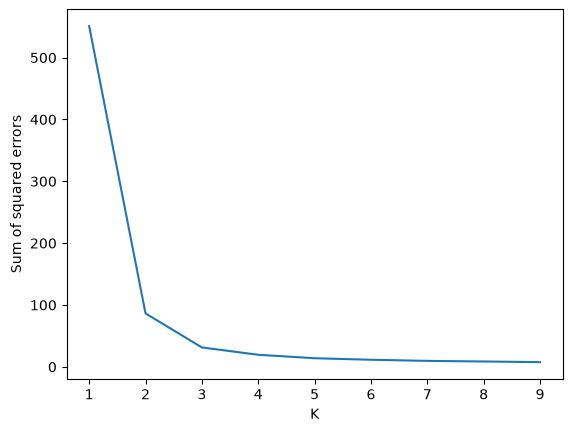

In [13]:
# from sklearn.cluster import KMeans
# sse = []
# k_rng = range(1, 10)
# for k in k_rng:
#     km = KMeans(n_clusters=k, random_state=42)
#     km.fit(X)
#     sse.append(km.inertia_)
# plt.plot(k_rng, sse); label the axes

from sklearn.cluster import KMeans
sse = []
k_range = range(1,10)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X)
    sse.append(km.inertia_)

plt.plot(k_range, sse)
plt.xlabel('K')
plt.ylabel('Sum of squared errors')

## Step 5 — Cluster with the best k and visualize

Using the `k` you picked from the elbow, run `KMeans`, add a `cluster` column, and scatter the points colored by cluster (plot the centroids too).

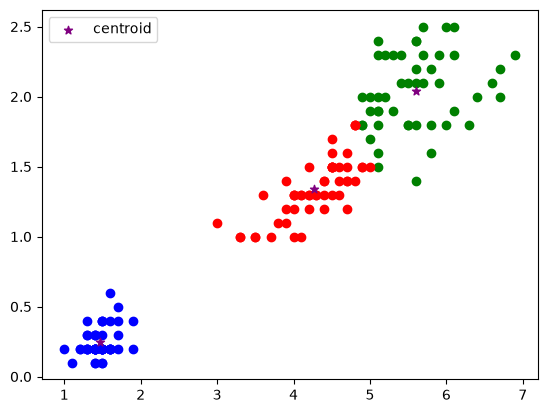

In [24]:
# km = KMeans(n_clusters=?, random_state=42)
# df['cluster'] = km.fit_predict(X)
# scatter each cluster in a different colour, plus km.cluster_centers_

km = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = km.fit_predict(X)

df1 = df[df.cluster == 0]
df2 = df[df.cluster == 1]
df3 = df[df.cluster == 2]

plt.scatter(df1.petal_length, df1.petal_width, color='green')
plt.scatter(df2.petal_length, df2.petal_width, color='blue')
plt.scatter(df3.petal_length, df3.petal_width, color='red')
plt.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1], color='purple', marker='*', label='centroid')
plt.legend()


In [25]:
pd.crosstab(df['cluster'], df['flower'])

flower,setosa,versicolor,virginica
cluster,,,
0,0,2,46
1,50,0,0
2,0,48,4


## Step 6 — Your conclusions

**Questions:**
1. What value of `k` did the elbow plot suggest?
2. Did scaling change the result much on this data? Why or why not?
3. **Peek at the labels:** run `pd.crosstab(df['cluster'], df['flower'])`. How well do your unsupervised clusters match the three real species?

_Your answers here..._

## Bonus challenge 🚀

- Repeat the whole thing using all **four** features. Does the elbow still point to the same `k`? (You can't scatter 4-D data, but the elbow plot still works.)